# P5. 우도와 최대우도: 데이터는 그대로 두고, 모수를 움직이면

**목표**
- 확률과 우도(likelihood)가 같은 식을 두 방향으로 읽은 것임을 그림으로 이해합니다.
- 로그 우도를 왜 쓰는지, 최대우도 추정값(MLE)이 왜 "표본 비율"과 "표본 평균"이 되는지 직접 유도합니다.
- 시퀀싱 read 와 염기 품질 점수로 genotype 0/0, 0/1, 1/1 의 우도를 계산합니다.

**이 노트북이 답하는 질문**: 데이터를 가장 잘 설명하는 모수는 무엇이고, "잘 설명한다"를 어떻게 숫자로 재나?

**같이 볼 강의·교재**
- McElreath, *Statistical Rethinking* 2023, 2강 "Garden of Forking Data" (1주차, 1–3장) [2]
- Downey, *Think Bayes* 2판, 4장 "Estimating Proportions" [3]
- Gelman 외, *Bayesian Data Analysis* 3판(BDA3), 1.3절 [1]

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito, 뜻 고정 — 사전 하늘, 우도 주황, 사후 파랑, 증거 진회색, 핵심 자주
import logging, math, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import stats, special

warnings.filterwarnings("ignore", category=RuntimeWarning)
COL = dict(prior="#56B4E9", likelihood="#E69F00", posterior="#0072B2", evidence="#374151",
           highlight="#CC79A7", ink="#222222", muted="#6B7280", grid="#E5E7EB", none="#D1D5DB",
           ok="#009E73", alt="#D55E00", ref="#9CA3AF", shade="#F3F4F6")

def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})

def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목'"""
    ax.set_title(f"{letter}   {title}")

def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)

def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨, 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)

def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.03):
    """수식을 조각으로 그린다. parts = [(mathtext, 색 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 아래 그림의 같은 색과 짝을 이룬다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); x = 0.0; items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:                                          # 이름표가 조각보다 넓으면 그만큼 자리를 더 준다
            lt = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = lt.get_window_extent(renderer=r).transformed(inv).width; lt.remove()
        slot = max(bb.width, lw)
        items.append((t, bb, color, label, x + (slot - bb.width) / 2)); x += slot + gap
    shift = (1 - (x - gap)) / 2                            # 가운데 정렬
    for t, bb, color, label, x0 in items:
        t.set_x(x0 + shift)
        if color:
            ax.add_patch(FancyBboxPatch((x0 + shift - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(x0 + shift + bb.width / 2, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)

def show_formula(parts, title=None, height=1.5, width=11):
    """수식 조각 그림만 한 장으로"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11.5, fontweight="semibold", transform=ax.transAxes)
    plt.show()

def concept_map(nodes, edges, title="Concept map", size=(11, 3.2)):
    """nodes = {key: (x, y, text, color)}, edges = [(from, to, label)] — 상자와 화살표"""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_axis_off()
    boxes = {}
    for k, (x, y, text, c) in nodes.items():
        t = ax.text(x, y, text, ha="center", va="center", fontsize=10, color=COL["ink"], zorder=3,
                    bbox=dict(boxstyle="round,pad=0.45", facecolor=c if c != "white" else "white",
                              alpha=0.25 if c != "white" else 1, edgecolor=c if c != "white" else COL["muted"],
                              linewidth=1.0))
        boxes[k] = t
    fig.canvas.draw(); r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted()
    ext = {}
    for k, t in boxes.items():                             # 상자 크기(축 좌표)
        bb = t.get_bbox_patch().get_window_extent(r).transformed(inv)
        ext[k] = (bb.x0, bb.y0, bb.x1, bb.y1)

    def edge_point(k, dx, dy):
        x0, y0, x1, y1 = ext[k]; cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        hw, hh = (x1 - x0) / 2 + 0.008, (y1 - y0) / 2 + 0.02
        s = min(hw / abs(dx) if dx else 1e9, hh / abs(dy) if dy else 1e9)
        return cx + dx * s, cy + dy * s

    for a, b, lab in edges:
        (ax0, ay0, ax1, ay1), (bx0, by0, bx1, by1) = ext[a], ext[b]
        ca, cb = ((ax0 + ax1) / 2, (ay0 + ay1) / 2), ((bx0 + bx1) / 2, (by0 + by1) / 2)
        dx, dy = cb[0] - ca[0], cb[1] - ca[1]
        p0 = edge_point(a, dx, dy); p1 = edge_point(b, -dx, -dy)
        ax.annotate("", xy=p1, xytext=p0, xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.0, mutation_scale=12,
                                    shrinkA=0, shrinkB=0), zorder=2)
        if lab:
            note(ax, (p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.05, lab, ha="center", fontsize=8.5,
                 transform=ax.transAxes)
    ax.set_title(title)
    plt.show()

def phred_to_e(q):
    """Phred 점수 → 오류 확률: Q = -10 log10(e) [Cock 2010]"""
    return 10 ** (-np.asarray(q, float) / 10)

apply_theme()

In [2]:
# 이 노트북의 그림 함수
def binom_lik(theta, n, x):
    return stats.binom.pmf(x, n, theta)

def draw_two_readings(n=10, x=7, thetas=(0.5, 0.7, 0.9)):
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0), gridspec_kw={"wspace": 0.28})
    k = np.arange(n + 1); th0 = 0.7
    pm = stats.binom.pmf(k, n, th0)
    ax[0].bar(k, pm, color=COL["none"], width=0.7)
    ax[0].bar([x], [pm[x]], color=COL["likelihood"], width=0.7)
    ax[0].set_xticks(k); ax[0].set_xlabel("number of heads x (data varies)")
    ax[0].set_ylabel(r"$P(x \mid \theta = 0.7)$"); ygrid(ax[0])
    panel(ax[0], "A", r"Probability: $\theta$ fixed at 0.7, data varies")
    note(ax[0], 0.2, pm.max() * 0.98, "bars add up to 1", va="top")
    th = np.linspace(0, 1, 401); L = binom_lik(th, n, x)
    ax[1].plot(th, L, color=COL["likelihood"], lw=2.2)
    for t in thetas:
        v = binom_lik(t, n, x)
        ax[1].plot([t], [v], "o", color=COL["likelihood"] if t == th0 else COL["ink"], ms=7, zorder=3)
        dx, ha = (0, "center") if t == th0 else ((-0.03, "right") if t < th0 else (0.03, "left"))   # 곡선을 피해 바깥쪽에
        ax[1].text(t + dx, v + 0.012, f"{v:.3f}", ha=ha, va="bottom", fontsize=9.5, color=COL["ink"])
    ax[1].set_xlabel(r"$\theta$ = chance of heads (parameter varies)")
    ax[1].set_ylabel(r"$L(\theta) = P(x = 7 \mid \theta)$"); ygrid(ax[1])
    ax[1].set_ylim(0, 0.33)
    panel(ax[1], "B", r"Likelihood: data fixed at x = 7, $\theta$ varies")
    callout(ax[1], 0.02, 0.215, "same formula,\nread the other way;\narea under this\ncurve is not 1", va="top")
    plt.show()

def draw_log_vs_raw(n=10, x=7):
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={"wspace": 0.35})
    th = np.linspace(0.01, 0.99, 400); L = binom_lik(th, n, x)
    ax[0].plot(th, L, color=COL["likelihood"], lw=2); ax[0].axvline(x / n, color=COL["muted"], ls=":", lw=1)
    ax[0].set_xlabel(r"$\theta$"); ax[0].set_ylabel(r"$L(\theta)$"); ygrid(ax[0])
    panel(ax[0], "A", "Likelihood")
    ax[1].plot(th, np.log(L), color=COL["likelihood"], lw=2); ax[1].axvline(x / n, color=COL["muted"], ls=":", lw=1)
    ax[1].set_xlabel(r"$\theta$"); ax[1].set_ylabel(r"$\log L(\theta)$"); ax[1].set_ylim(-12, 0); ygrid(ax[1])
    panel(ax[1], "B", "Log-likelihood")
    callout(ax[1], 0.17, -11.2, "peak at the same place (0.7)", fontsize=9.5)
    ns = np.arange(50, 2001, 50)
    prod = np.array([np.prod(np.full(m, 0.5)) for m in ns])
    ax[2].semilogy(ns[prod > 0], prod[prod > 0], color=COL["ink"], lw=2)
    zero = ns[prod == 0]
    ax[2].axvspan(zero.min(), ns.max(), color=COL["shade"], lw=0)
    note(ax[2], zero.min() + 40, 1e-150, "product of 0.5's\nbecomes exactly 0\n(underflow)", va="center", color=COL["ink"])
    ax[2].set_xlabel("number of reads multiplied"); ax[2].set_ylabel("product of probabilities")
    panel(ax[2], "C", "Why logs: tiny numbers underflow")
    plt.show()

def draw_mle_and_poisson(n=10, x=7, counts=None):
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"wspace": 0.3})
    th = np.linspace(0.01, 0.99, 400)
    ll = x * np.log(th) + (n - x) * np.log(1 - th)
    ax[0].plot(th, ll, color=COL["likelihood"], lw=2); ax[0].axvline(x / n, color=COL["highlight"], lw=1.4)
    ax[0].set_ylim(ll.max() - 8, ll.max() + 1); ygrid(ax[0])
    ax[0].set_xlabel(r"$\theta$"); ax[0].set_ylabel(r"$\log L(\theta)$ + const")
    callout(ax[0], x / n - 0.02, ll.max() - 7.3, f"MLE = x / n = {x}/{n} = {x / n:.1f}", fontsize=9.5, ha="right")
    panel(ax[0], "A", "Binomial: coin flips, or alt reads out of total")
    lam = np.linspace(counts.mean() * 0.7, counts.mean() * 1.3, 400)
    llp = counts.sum() * np.log(lam) - len(counts) * lam
    ax[1].plot(lam, llp - llp.max(), color=COL["likelihood"], lw=2)
    ax[1].axvline(counts.mean(), color=COL["highlight"], lw=1.4)
    ax[1].set_ylim(-40, 3); ygrid(ax[1])
    ax[1].set_xlabel(r"$\lambda$ = mean reads per window"); ax[1].set_ylabel(r"$\log L(\lambda)$ (max set to 0)")
    callout(ax[1], 0.02, 0.97, f"MLE =\nsample mean\n= {counts.mean():.2f}", fontsize=9.5, ha="left", va="top",
            transform=ax[1].transAxes)
    panel(ax[1], "B", f"Poisson: read counts in {len(counts)} windows")
    plt.show()

def draw_sharpening(p=0.7, ns=(10, 100, 1000)):
    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    th = np.linspace(0.3, 1, 600); greys = ["#9CA3AF", "#6B7280", COL["ink"]]
    for m, c, yl in zip(ns, greys, (0.35, 0.6, 0.85)):
        k = int(round(p * m))
        ll = k * np.log(th) + (m - k) * np.log(1 - th)
        L = np.exp(ll - ll.max())
        ax.plot(th, L, color=c, lw=2)
        j = np.argmin(np.abs(L[th > p] - yl)); xr = th[th > p][j]
        ax.text(xr + 0.008, yl, f"n = {m}", color=c, fontsize=9.5, va="center", fontweight="semibold",
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_xlabel(r"$\theta$"); ax.set_ylabel("likelihood / its maximum"); ygrid(ax)
    panel(ax, "", "Same proportion (70%), more data: the peak gets narrower")
    callout(ax, 0.31, 0.92, "more reads → less uncertainty about θ", va="top")
    plt.show()

def draw_lr(n=10, x=7, t1=0.7, t2=0.5):
    th = np.linspace(0.01, 0.99, 400); L = binom_lik(th, n, x)
    l1, l2 = binom_lik(t1, n, x), binom_lik(t2, n, x)
    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    ax.plot(th, L, color=COL["likelihood"], lw=2)
    for t, v in [(t1, l1), (t2, l2)]:
        ax.vlines(t, 0, v, color=COL["ink"], lw=1.4, ls=(0, (3, 2)))
        ax.plot([t], [v], "o", color=COL["ink"], ms=6)
        ha, dx = ("center", 0) if t == t1 else ("right", -0.02)           # 오르막의 점은 왼쪽 위에 써서 곡선을 피함
        ax.text(t + dx, v + 0.01, rf"$L({t})={v:.3f}$", ha=ha, va="bottom", fontsize=9.5)
    ax.set_ylim(0, 0.33); ygrid(ax)
    ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"$L(\theta)$")
    callout(ax, 0.02, 0.30, f"L(0.7) / L(0.5) = {l1 / l2:.2f}:\nθ = 0.7 explains 7/10 heads {l1 / l2:.1f}x better", va="top")
    panel(ax, "", "Likelihood ratio: compare two values of θ on the same data")
    plt.show()

def genotype_loglik(is_alt, q):
    """Li 2011 식 (2), 이배체(m=2). g = 참조 대립유전자 수 (2 = 0/0, 1 = 0/1, 0 = 1/1). 자연로그 반환."""
    e = phred_to_e(q); is_alt = np.asarray(is_alt, bool)
    out = {}
    for name, g in [("0/0", 2), ("0/1", 1), ("1/1", 0)]:
        p_ref = (g * (1 - e) + (2 - g) * e) / 2       # 참조 염기로 읽힐 확률
        p_alt = ((2 - g) * (1 - e) + g * e) / 2       # 변이 염기로 읽힐 확률
        out[name] = np.sum(np.where(is_alt, np.log(p_alt), np.log(p_ref)))
    return out

def draw_genotype_likelihood(n_reads=10, n_alt=3, quals=(30, 10)):
    is_alt = np.array([False] * (n_reads - n_alt) + [True] * n_alt)
    order = np.random.default_rng(4).permutation(n_reads); is_alt = is_alt[order]
    fig = plt.figure(figsize=(12, 4.3))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 1.25, 1.25], wspace=0.35)
    ax = fig.add_subplot(gs[0])
    for i, a in enumerate(is_alt):
        ax.add_patch(FancyBboxPatch((0.1, i + 0.15), 0.8, 0.7, boxstyle="round,pad=0,rounding_size=0.12",
                                    color=COL["alt"] if a else COL["ref"], lw=0))
        ax.text(0.5, i + 0.5, "T" if a else "C", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    ax.set_xlim(-0.2, 1.4); ax.set_ylim(n_reads + 0.3, -0.3); ax.set_axis_off()
    note(ax, 1.0, 1.0, "C = reference\n(grey)", va="center", color=COL["ink"])
    note(ax, 1.0, n_reads - 2, "T = alt\n(red)", va="center", color=COL["alt"])
    panel(ax, "A", f"{n_reads} reads at one site")
    for j, q in enumerate(quals):
        ax = fig.add_subplot(gs[j + 1])
        ll = genotype_loglik(is_alt, q); names = list(ll)
        v = np.array([ll[k] for k in names]) / np.log(10)
        rel = v - v.max()
        ax.barh(names, rel, color=COL["likelihood"], height=0.55)
        lo = min(rel.min() * 1.22, -1.5)
        for yy, r in enumerate(rel):
            ax.text(r + lo * 0.02, yy, f"{r:.1f}", va="center", ha="right", fontsize=9.5, color=COL["ink"])
        ax.set_xlim(lo, 0.4); ax.invert_yaxis()
        ax.set_xlabel(r"$\log_{10} L(g)$ minus the best genotype"); ax.axvline(0, color=COL["muted"], lw=0.8)
        panel(ax, "BC"[j], f"every base Q{q} (error {phred_to_e(q):g})")
        best = names[int(np.argmax(v))]; second = sorted(rel)[-2]
        callout(ax, lo * 0.5, 1, f"{best} wins by {-second:.1f} log10 units\n= {10 ** -second:,.0f}x", ha="center",
                va="center", fontsize=9.5)
    plt.show()
    return is_alt

## 개념 지도

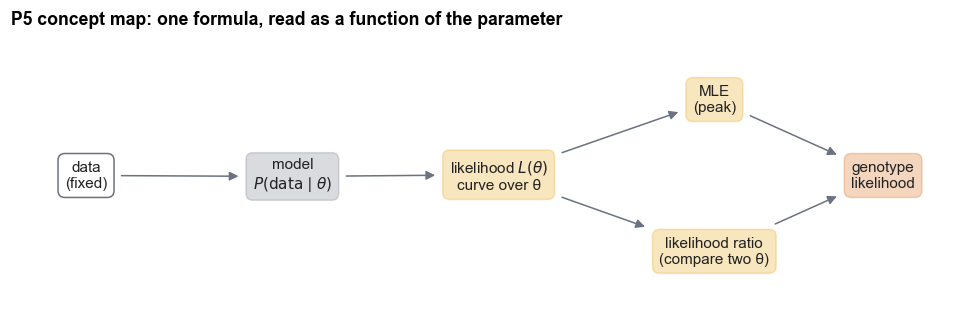

In [3]:
concept_map(
    {"data": (0.08, 0.5, "data\n(fixed)", "white"),
     "model": (0.30, 0.5, r"model" "\n" r"$P(\mathrm{data}\mid\theta)$", COL["muted"]),
     "lik": (0.52, 0.5, r"likelihood $L(\theta)$" "\n" "curve over θ", COL["likelihood"]),
     "mle": (0.75, 0.78, "MLE\n(peak)", COL["likelihood"]),
     "lr": (0.75, 0.22, "likelihood ratio\n(compare two θ)", COL["likelihood"]),
     "geno": (0.93, 0.5, "genotype\nlikelihood", COL["alt"])},
    [("data", "model", ""), ("model", "lik", ""), ("lik", "mle", ""),
     ("lik", "lr", ""), ("mle", "geno", ""), ("lr", "geno", "")],
    title="P5 concept map: one formula, read as a function of the parameter")

**그림에서 볼 것**: 데이터는 고정하고, 확률 모형을 "모수 θ 의 함수"로 읽은 것이 우도입니다. 우도 곡선의 꼭대기가 MLE 이고, 두 θ 의 높이를 나눈 것이 우도비입니다. 마지막에 이 둘을 read 와 품질 점수에 적용해 genotype 을 비교합니다.

## 먼저 알아 둘 것

**기호 사전**

| 기호 | 읽는 법 | 뜻 |
|---|---|---|
| $\theta$ | 세타 | 모수(parameter). 모형의 손잡이. 동전이 앞면일 확률, 종양 VAF 처럼 우리가 모르는 값 |
| $P(x \mid \theta)$ | "θ 일 때 x 의 확률" | 세로 막대 $\mid$ 오른쪽은 "이미 정해졌다고 놓는 것" |
| $\binom{n}{x}$ | n 개 중 x 개 고르기 | 순서를 따지지 않을 때 경우의 수. $\binom{10}{7} = 120$ |
| $\prod_{j=1}^{k}$ | 곱하기 기호(파이) | j 를 1 부터 k 까지 바꾸며 뒤의 것을 모두 곱합니다 |
| $\arg\max_\theta$ | 아그맥스 | "값을 가장 크게 만드는 θ". 최댓값 자체가 아니라 **그 자리** |
| $\log$ | 로그(이 노트북은 자연로그 ln) | 곱을 합으로 바꿉니다: $\log(ab) = \log a + \log b$ |

## 1. 확률과 우도: 같은 식을 두 방향으로 읽기

**한 줄 정의**: 우도는 "관측한 데이터가 모수 θ 에서 나올 확률"을 **θ 의 함수로** 본 것입니다. BDA3 는 이를 "$p(y\mid\theta)$ 를 y 를 고정하고 θ 의 함수로 볼 때 likelihood function 이라 부른다"고 정의합니다 [1].

**왜 필요한가**: 우리는 대개 모수를 모릅니다(종양 VAF, purity, genotype). 데이터는 이미 손에 있습니다. 그러면 "어떤 θ 가 이 데이터를 더 잘 설명하나?"를 비교할 잣대가 필요하고, 그 잣대가 우도입니다.

**숫자로 따라가기**: 동전을 10 번 던져 앞면이 7 번 나왔습니다.

| θ (앞면 확률 후보) | $\binom{10}{7}\theta^7(1-\theta)^3$ | 우도 |
|---|---|---|
| 0.5 | 120 × 0.5⁷ × 0.5³ | 0.117 |
| 0.7 | 120 × 0.7⁷ × 0.3³ | 0.267 |
| 0.9 | 120 × 0.9⁷ × 0.1³ | 0.057 |

셋 중 θ = 0.7 이 "앞면 7 번"을 가장 잘 설명합니다.

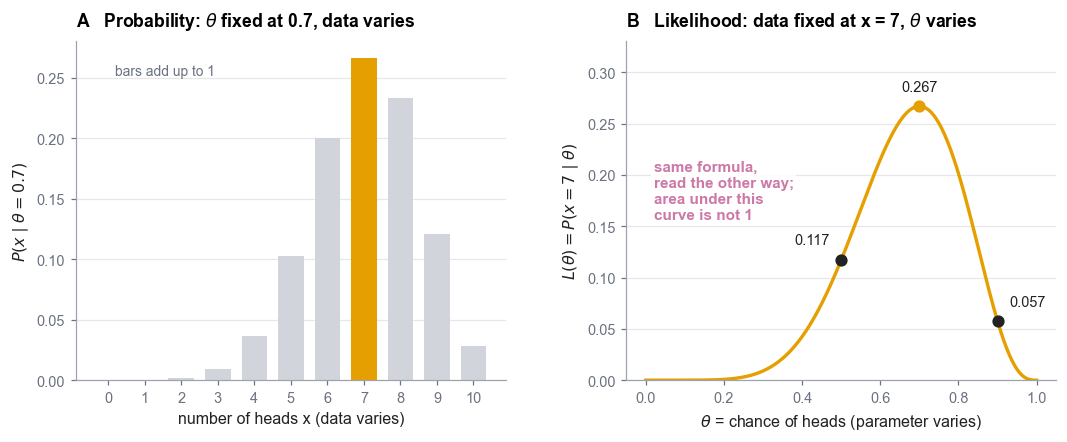

In [4]:
draw_two_readings()

**그림에서 볼 것**
- A: θ 를 0.7 로 **고정**하면, 가능한 데이터 0~10 번에 확률이 나뉘고 막대를 모두 더하면 1 입니다. 주황 막대가 우리가 본 "7 번"입니다.
- B: 이번에는 데이터를 "7 번"으로 **고정**하고 θ 를 0 에서 1 까지 움직였습니다. 주황 곡선이 우도입니다. 점 세 개가 위 표의 0.117, 0.267, 0.057 입니다.
- A 의 주황 막대 높이(0.267)와 B 의 θ = 0.7 점 높이는 같은 숫자입니다. 같은 식을 어느 쪽을 고정하고 읽느냐만 다릅니다.
- B 곡선 아래 넓이는 1 이 아닙니다. 우도는 θ 에 대한 확률 분포가 아니기 때문입니다(아래에서 확인).

**수식 풀어 읽기**

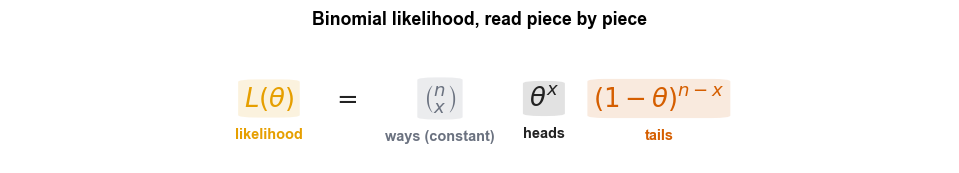

In [5]:
show_formula([
    (r"$L(\theta)$", COL["likelihood"], "likelihood"),
    (r"$=$", None, None),
    (r"$\binom{n}{x}$", COL["muted"], "ways (constant)"),
    (r"$\theta^{x}$", COL["ink"], "heads"),
    (r"$(1-\theta)^{n-x}$", COL["alt"], "tails"),
], title="Binomial likelihood, read piece by piece")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $L(\theta)$ | "세타의 우도" | 데이터(7/10)가 θ 에서 나올 확률 | B 의 주황 곡선 높이 |
| $\binom{n}{x}$ | "10 개 중 7 개 고르기" | 앞면 7 번이 나오는 순서의 수(120). θ 와 상관없는 상수 | 곡선 모양은 바꾸지 않고 높이만 키움 |
| $\theta^{x}$ | "세타의 x 제곱" | 앞면이 7 번 각각 θ 확률로 나옴 | θ 가 클수록 커짐 → 곡선 오른쪽을 올림 |
| $(1-\theta)^{n-x}$ | "1 빼기 세타의 3 제곱" | 뒷면이 3 번 각각 1−θ 확률로 나옴 | θ 가 1 에 가까우면 0 으로 → 곡선 오른쪽 끝을 내림 |

**숫자 넣기**: θ = 0.7 이면 $120 \times 0.0824 \times 0.027 = 0.267$.

**시뮬레이션으로 확인**: θ = 0.7 인 동전으로 "10 번 던지기"를 20 만 번 해서, 앞면이 정확히 7 번인 비율이 0.267 근처인지 봅니다. 그리고 B 곡선 아래 넓이를 직접 적분해, 1 이 아니라 $1/(n+1) = 0.0909$ 임을 확인합니다(이 노트북에서 계산한 값).

In [6]:
rng = np.random.default_rng(0)
sim = rng.binomial(10, 0.7, size=200_000)
p_sim = np.mean(sim == 7)
p_formula = stats.binom.pmf(7, 10, 0.7)
print(f"formula {p_formula:.4f}  simulation {p_sim:.4f}")
assert abs(p_sim - p_formula) < 0.005

from scipy import integrate
area, _ = integrate.quad(lambda t: stats.binom.pmf(7, 10, t), 0, 1)
print(f"area under the likelihood curve = {area:.4f}  (1/(n+1) = {1/11:.4f})")
assert abs(area - 1 / 11) < 1e-6

formula 0.2668  simulation 0.2672
area under the likelihood curve = 0.0909  (1/(n+1) = 0.0909)


**직접 바꿔 보기**: 아래에서 `n`, `x` 를 바꿔 보세요(예: 40 번 중 12 번). 곡선의 꼭대기는 늘 $x/n$ 에 있습니다.

In [7]:
# draw_two_readings(n=40, x=12, thetas=(0.2, 0.3, 0.5))

> **시퀀싱 데이터에서는**: 어떤 자리에서 read 30 개 중 9 개가 변이 염기라면, 이것은 "30 번 던져 9 번 앞면"과 같은 모양입니다. θ 자리에 "이 자리의 변이 allele 비율(VAF)"이 들어갑니다. P7 과 P9 에서 이 VAF 우도에 purity·CN 을 넣어 CCF 를 구합니다.

## 2. 로그 우도: 곱을 합으로

**한 줄 정의**: 로그 우도는 우도에 로그를 씌운 것입니다. $\log L(\theta) = x\log\theta + (n-x)\log(1-\theta) + \text{상수}$.

**왜 필요한가**
- read 하나하나의 확률을 곱하면 숫자가 금방 컴퓨터가 표현할 수 없을 만큼 작아집니다(**underflow**, 0 으로 떨어짐).
- 로그를 씌우면 곱이 합이 되어 이런 문제가 없습니다.
- 로그는 커지는 순서를 바꾸지 않는 함수라서, **꼭대기의 위치(θ)는 그대로**입니다.

**숫자로 따라가기**: 0.5 를 1,000 번 곱하면 약 $9 \times 10^{-302}$ 이고, 1,100 번 곱하면 컴퓨터에서 정확히 0 이 됩니다. 로그로는 $1100 \times \log 0.5 = -762.5$ 로 아무 문제가 없습니다.

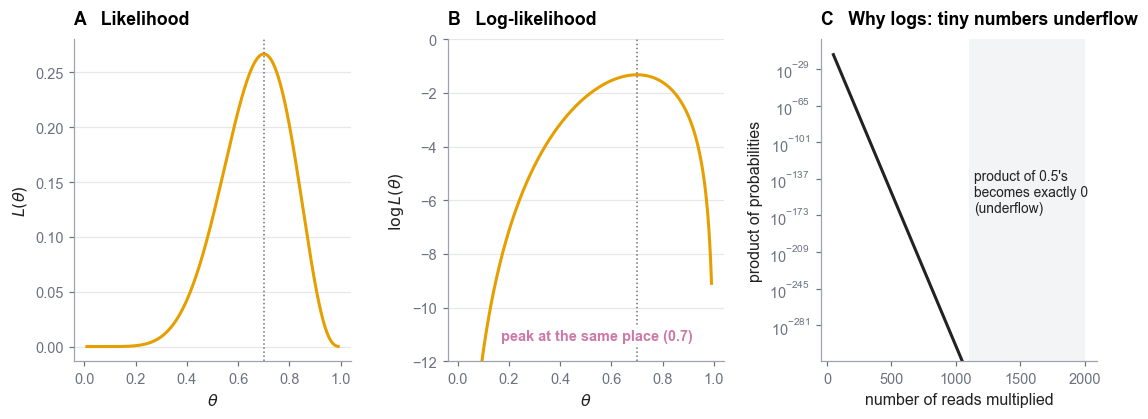

0.5^1000 = 9.33e-302,  0.5^1100 = 0.0,  1100*log(0.5) = -762.5,  0.001^100 = 1e-300


In [8]:
draw_log_vs_raw()
p1000 = np.prod(np.full(1000, 0.5)); p1100 = np.prod(np.full(1100, 0.5))
p_err100 = np.prod(np.full(100, 0.001))
print(f"0.5^1000 = {p1000:.3g},  0.5^1100 = {p1100},  1100*log(0.5) = {1100 * np.log(0.5):.1f},  0.001^100 = {p_err100:.3g}")
assert p1000 > 0 and p1100 == 0.0 and abs(np.log10(p_err100) + 300) < 1e-6

**그림에서 볼 것**
- A 와 B: 우도와 로그 우도는 모양이 다르지만, 꼭대기는 둘 다 0.7(점선)에 있습니다.
- C: 0.5 짜리 확률을 몇 개 곱하느냐에 따라 결과가 내려가다가, 약 1,075 개를 넘으면(옅은 회색 구간) 정확히 0 이 됩니다. 1,000 개는 아직 0 이 아니지만(위 출력 $9\times10^{-302}$), 깊이 110x 자리 열 곳(read 1,100 개)이면 이 영역에 들어갑니다.
- read 하나의 확률이 0.5 보다 작으면 0 에 더 빨리 닿습니다. 예를 들어 오류 확률 0.001 짜리 read 는 100 개만 곱해도 $10^{-300}$ 입니다.

**수식 풀어 읽기**

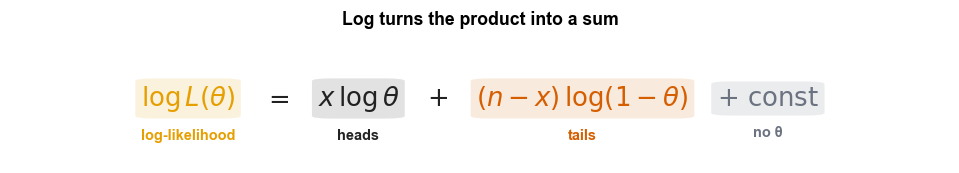

In [9]:
show_formula([
    (r"$\log L(\theta)$", COL["likelihood"], "log-likelihood"),
    (r"$=$", None, None),
    (r"$x\,\log\theta$", COL["ink"], "heads"),
    (r"$+$", None, None),
    (r"$(n-x)\,\log(1-\theta)$", COL["alt"], "tails"),
    (r"$+\ \mathrm{const}$", COL["muted"], "no θ"),
], title="Log turns the product into a sum")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $x\log\theta$ | "x 곱하기 로그 세타" | 앞면 하나마다 $\log\theta$ 를 더함 | B 곡선의 오른쪽 오르막 |
| $(n-x)\log(1-\theta)$ | "뒷면 수 곱하기 로그 1 빼기 세타" | 뒷면 하나마다 $\log(1-\theta)$ 를 더함 | θ→1 에서 −∞ 로 떨어지는 오른쪽 끝 |
| const | 상수 | θ 와 상관없는 부분. 비교할 때는 빼도 됨 | 곡선을 위아래로만 옮김 |

## 3. 최대우도 추정(MLE): 꼭대기를 찾기

**한 줄 정의**: 최대우도 추정값 $\hat\theta = \arg\max_\theta L(\theta)$ 는 우도를 가장 크게 만드는 θ 입니다($\hat\theta$ 는 "세타 햇", 추정값이라는 뜻).

**왜 필요한가**: 모수 하나를 숫자 하나로 보고하고 싶을 때 가장 흔히 쓰는 답입니다. PURPLE 의 purity 처럼 "데이터를 가장 잘 설명하는 값"을 고르는 생각과 같은 계열입니다. 다만 PURPLE 은 우도 대신 벌점 점수를 씁니다. 설명서는 정수 CN 에서 벗어난 정도의 벌점(deviation penalty), 이배체 이형접합에서 벗어난 사건의 벌점(event penalty), 체세포 SNV copy 수의 벌점을 합친 fit score 가 가장 작은 purity·ploidy 를 고른다고 적습니다 [7].

**숫자로 따라가기(직접 유도)**: 로그 우도의 기울기가 0 인 곳이 꼭대기입니다.

| 단계 | 식 | 말로 |
|---|---|---|
| 1 | $\frac{d}{d\theta}\log L = \frac{x}{\theta} - \frac{n-x}{1-\theta}$ | 앞면은 θ 를 올리고 싶어 하고, 뒷면은 내리고 싶어 함 |
| 2 | $\frac{x}{\theta} = \frac{n-x}{1-\theta}$ | 둘이 균형을 이루는 곳 |
| 3 | $x(1-\theta) = (n-x)\theta \Rightarrow \hat\theta = x/n$ | 정리하면 **표본 비율** |

포아송(Poisson, 일정한 평균 λ 로 흩어지는 개수의 분포)도 같은 방법으로 풉니다. 창 $i$ 의 read 수 $y_i$ 가 Poisson(λ) 이면
$\log L(\lambda) = \sum_i y_i \log\lambda - n\lambda + \text{상수}$, 기울기 $\sum y_i/\lambda - n = 0$ 에서 $\hat\lambda = \bar y$ (**표본 평균**)입니다.

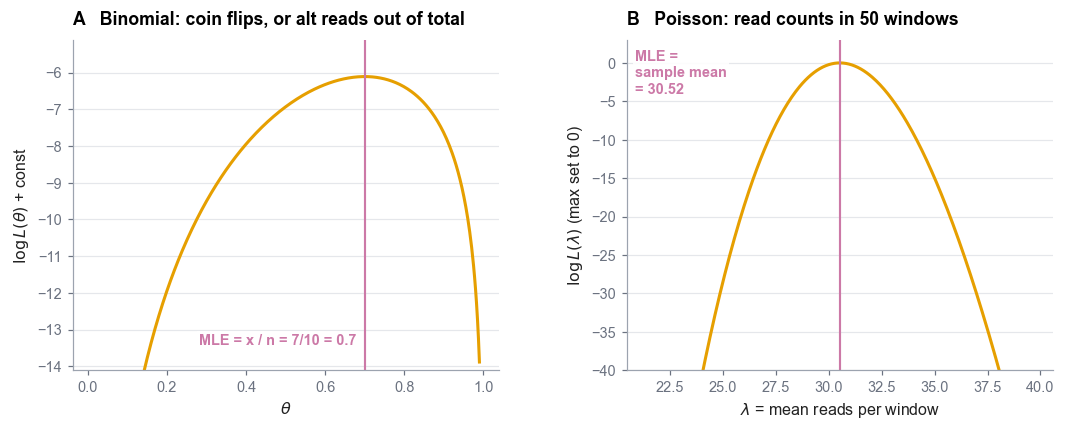

binomial: numerical MLE 0.7000 vs x/n = 0.7
Poisson : numerical MLE 30.5200 vs sample mean = 30.5200


In [10]:
rng = np.random.default_rng(1)
depth_counts = rng.poisson(30, size=50)        # 1 kb 창 50 개의 read 수(평균 30 인 장난감)
draw_mle_and_poisson(counts=depth_counts)

from scipy.optimize import minimize_scalar
res_b = minimize_scalar(lambda t: -(7 * np.log(t) + 3 * np.log(1 - t)), bounds=(1e-6, 1 - 1e-6), method="bounded")
res_p = minimize_scalar(lambda l: -(depth_counts.sum() * np.log(l) - len(depth_counts) * l), bounds=(1, 100), method="bounded")
print(f"binomial: numerical MLE {res_b.x:.4f} vs x/n = 0.7")
print(f"Poisson : numerical MLE {res_p.x:.4f} vs sample mean = {depth_counts.mean():.4f}")
assert abs(res_b.x - 0.7) < 1e-4 and abs(res_p.x - depth_counts.mean()) < 1e-3

**그림에서 볼 것**
- A: 이항 로그 우도의 꼭대기(자주색 선)가 정확히 7/10 = 0.7 입니다.
- B: 평균 30 인 포아송에서 뽑은 창 50 개의 read 수로 λ 의 로그 우도를 그렸습니다. 꼭대기가 표본 평균과 같습니다.
- 숫자로 꼭대기를 찾은 값(minimize_scalar)과 유도한 식의 값이 같다는 것을 위 assert 가 확인했습니다.

**데이터가 늘면 꼭대기가 뾰족해진다**: 비율은 같아도(70%) 데이터가 많을수록 우도가 좁은 범위에 몰립니다. 이 폭이 "θ 를 얼마나 확실히 아는가"를 나타냅니다.

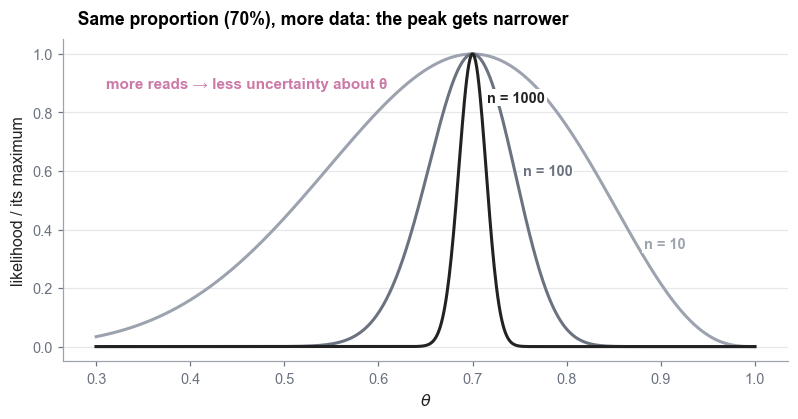

In [11]:
draw_sharpening()

**그림에서 볼 것**: 세 곡선 모두 꼭대기는 0.7 입니다. n = 10(옅은 회색)은 0.4~0.9 를 다 받아 주지만, n = 1000(검정)은 0.67~0.73 근처로 좁습니다. 깊이 10x 와 1000x 에서 같은 VAF 30% 를 보았을 때 확신의 차이가 이것입니다.

> **시퀀싱 데이터에서는**: 창마다의 read 수는 대략 포아송을 따르고(B0 의 깊이 흔들림), 평균 깊이 추정은 포아송 MLE 입니다. 실제 깊이는 조각의 GC 함량에 따라 평균부터 달라지므로(GC 가 아주 높거나 낮은 조각은 덜 읽힘 [8]), 창마다 같은 λ 를 두는 포아송 하나보다 더 퍼집니다(과분산). 이는 P3 의 음이항과 P7 의 베타–이항에서 다룹니다.

## 4. 우도비: 두 후보를 같은 데이터로 비교하기

**한 줄 정의**: 우도비 $\frac{L(\theta_1)}{L(\theta_2)}$ 는 "θ₁ 이 θ₂ 보다 이 데이터를 몇 배 잘 설명하나"입니다.

**왜 필요한가**: "이 자리는 이형접합인가, 동형접합인가?", "이 변이는 진짜인가, 시퀀싱 오류인가?"처럼 후보 두 개를 비교하는 일이 시퀀싱 분석의 대부분입니다. 상수 $\binom{n}{x}$ 는 나눌 때 지워져서 비교가 깔끔해집니다.

**숫자로 따라가기**: 7/10 에서 $L(0.7)/L(0.5) = 0.267/0.117 = 2.28$.

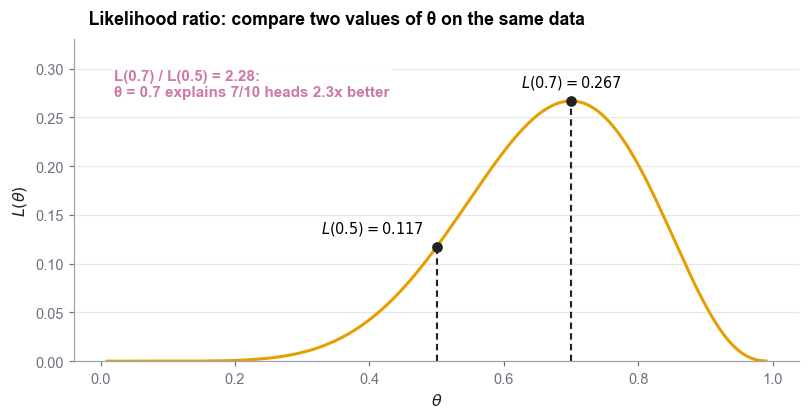

LR = 2.277;  without the binomial coefficient = 2.277


In [12]:
draw_lr()
lr = stats.binom.pmf(7, 10, 0.7) / stats.binom.pmf(7, 10, 0.5)
lr_no_const = (0.7 ** 7 * 0.3 ** 3) / (0.5 ** 10)
print(f"LR = {lr:.3f};  without the binomial coefficient = {lr_no_const:.3f}")
assert abs(lr - lr_no_const) < 1e-12

**그림에서 볼 것**: 두 점선 높이의 비가 우도비 2.28 입니다. 이 비는 θ = 0.7 이 "옳다"는 확률이 아닙니다. 그 확률을 말하려면 사전 지식(사전확률)이 더 필요하고, 그것이 P6 의 베이즈 정리입니다.

**수식 풀어 읽기**

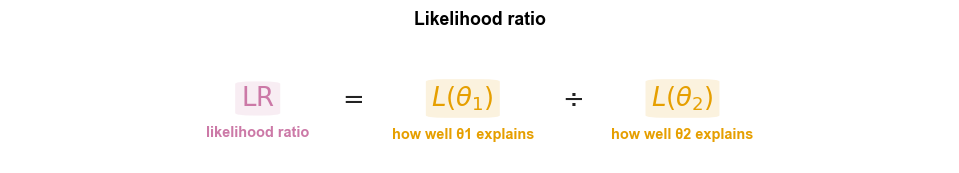

In [13]:
show_formula([
    (r"$\mathrm{LR}$", COL["highlight"], "likelihood ratio"),
    (r"$=$", None, None),
    (r"$L(\theta_1)$", COL["likelihood"], "how well θ1 explains"),
    (r"$\div$", None, None),
    (r"$L(\theta_2)$", COL["likelihood"], "how well θ2 explains"),
], title="Likelihood ratio")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $L(\theta_1)$ | "세타 1 의 우도" | 후보 1 에서 이 데이터가 나올 확률 | θ = 0.7 점선 높이 |
| $L(\theta_2)$ | "세타 2 의 우도" | 후보 2 에서 이 데이터가 나올 확률 | θ = 0.5 점선 높이 |
| LR | 우도비 | 1 보다 크면 후보 1 쪽 | 두 높이의 비 |

> **시퀀싱 데이터에서는**: Mutect2 가 VCF 에 쓰는 `TLOD` 는 "변이 allele 이 있다"는 모형과 "없다"는 모형의 **로그 증거비**(log evidence ratio)입니다. 기술 문서는 이를 "the log odds that an allele exists"라고 설명합니다 [6]. 여기서의 우도비와 같은 생각이고, 다만 allele 비율을 하나로 고정하지 않고 가능한 값 전체로 평균(적분)한다는 점이 다릅니다. P9 에서 자세히 봅니다.

## 5. 시퀀싱: read 와 품질 점수로 genotype 우도 구하기

**먼저 알아 둘 것: Phred 품질 점수**. 염기 하나의 품질 점수 Q 는 그 염기가 틀렸을 확률 $P_e$ 로 정의됩니다: $Q = -10\log_{10} P_e$ [5]. 그래서 Q30 은 오류 확률 0.001, Q20 은 0.01, Q10 은 0.1 입니다.

**한 줄 정의**: genotype 우도 $L(g)$ 는 "이 자리의 진짜 genotype 이 $g$ 일 때, 지금 보이는 read 염기들이 나올 확률"입니다.

**왜 필요한가**: read 를 몇 개 세는 것만으로는 부족합니다. 같은 "10 개 중 변이 3 개"라도 변이 염기의 품질이 좋으면(Q30) 우연한 오류로 보기 어렵고, 품질이 나쁘면(Q10) 오류일 수 있습니다. 우도는 품질을 자동으로 반영합니다.

**모형** (Li 2011 [4], 2.2 절 식 (2)). 이배체에서 $g$ 를 **참조 allele 개수**로 둡니다(0/0 → g = 2, 0/1 → g = 1, 1/1 → g = 0). 각 read 는 두 염색체 중 하나에서 반반 확률로 나오고, 염기는 확률 $\epsilon_j$ 로 틀리게 읽힌다고 봅니다. 이 논문은 한 자리에서 가장 많이 보인 두 염기만 남기므로, 틀린 염기는 "다른 쪽 allele"로 읽힌다고 봅니다(**두 염기 가정**).

**두 염기 가정이 바꾸는 것**: 틀린 염기가 나머지 세 염기 중 하나로 고르게 간다고 보면(오류 하나가 변이 염기 T 를 만들 확률 $\epsilon/3$), 0/0 자리에서 T 가 보이기가 세 배 어려워집니다. 아래 예(10 개 중 T 3 개, Q10)에서 0/1 : 0/0 우도비는 두 염기 가정으로 약 2.0, $\epsilon/3$ 가정으로 약 27.7 입니다(아래 셀에서 계산). 어느 가정을 쓰느냐가 결과를 바꾸므로, 도구가 어떤 오류 모형을 쓰는지 확인해야 합니다.

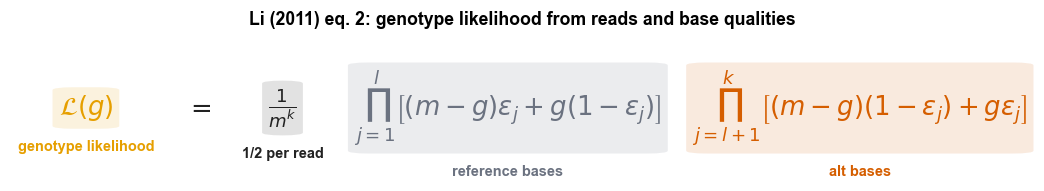

In [14]:
show_formula([
    (r"$\mathcal{L}(g)$", COL["likelihood"], "genotype likelihood"),
    (r"$=$", None, None),
    (r"$\frac{1}{m^{k}}$", COL["ink"], "1/2 per read"),
    (r"$\prod_{j=1}^{l}\left[(m-g)\epsilon_j + g(1-\epsilon_j)\right]$", COL["muted"], "reference bases"),
    (r"$\prod_{j=l+1}^{k}\left[(m-g)(1-\epsilon_j) + g\epsilon_j\right]$", COL["alt"], "alt bases"),
], title="Li (2011) eq. 2: genotype likelihood from reads and base qualities", height=1.7, width=12)

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $m$ | 엠 | ploidy(염색체 수). 사람 상염색체는 2 | — |
| $g$ | 지 | 참조 allele 개수 (0, 1, 2) | B, C 의 세 막대 |
| $k$, $l$ | 케이, 엘 | 이 자리를 덮는 read 수, 그중 참조 염기 수 | A 의 막대 10 개, 그중 회색 7 개 |
| $\epsilon_j$ | 엡실론 j | j 번째 염기가 틀렸을 확률 = $10^{-Q_j/10}$ | 패널 제목의 error |
| $(m-g)\epsilon_j + g(1-\epsilon_j)$ | | 참조 염기가 보일 확률 × m: 참조 염색체에서 맞게 읽히거나, 변이 염색체에서 틀리게 읽힘 | A 의 회색 막대 하나 |
| $(m-g)(1-\epsilon_j) + g\epsilon_j$ | | 변이 염기가 보일 확률 × m | A 의 빨간 막대 하나 |

**숫자 넣기** (read 10 개, 그중 변이 3 개, 모두 같은 품질)

| genotype | Q30 (ε = 0.001) | Q10 (ε = 0.1) |
|---|---|---|
| 0/0 (g = 2) | $0.999^7 \times 0.001^3 \approx 1.0\times10^{-9}$ | $0.9^7 \times 0.1^3 \approx 4.8\times10^{-4}$ |
| 0/1 (g = 1) | $0.5^{10} \approx 9.8\times10^{-4}$ | $0.5^{10} \approx 9.8\times10^{-4}$ |
| 1/1 (g = 0) | $0.001^7 \times 0.999^3 \approx 10^{-21}$ | $0.1^7 \times 0.9^3 \approx 7.3\times10^{-8}$ |

이 확률은 "정해진 순서의 read 묶음"의 확률이라 조합 수 $\binom{10}{3}$ 가 없습니다. 세 genotype 을 비교할 때는 같은 상수라 상관없습니다.

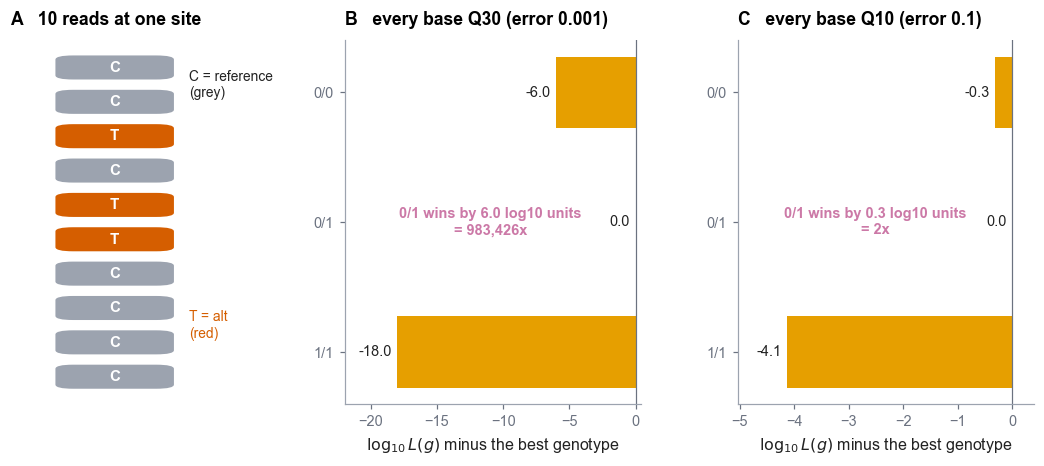

Q30: 0/0 9.93e-10, 0/1 9.77e-04, 1/1 9.97e-22
Q10: 0/0 4.78e-04, 0/1 9.77e-04, 1/1 7.29e-08
Q10, 3 alt of 10: LR(0/1 : 0/0) two-base 2.0,  error spread over 3 bases (e/3) 27.7


In [15]:
is_alt = draw_genotype_likelihood()
ll30 = genotype_loglik(is_alt, 30); ll10 = genotype_loglik(is_alt, 10)
for q, ll in [(30, ll30), (10, ll10)]:
    print(f"Q{q}: " + ", ".join(f"{g} {np.exp(v):.2e}" for g, v in ll.items()))
assert abs(np.exp(ll30["0/1"]) - 0.5 ** 10) < 1e-12
assert abs(np.exp(ll30["0/0"]) - 0.999 ** 7 * 0.001 ** 3) < 1e-15
assert abs(np.exp(ll10["0/0"]) - 0.9 ** 7 * 0.1 ** 3) < 1e-12
e10 = 0.1                                                    # 두 염기 가정 vs 오류가 세 염기로 고르게(ε/3)
lr_two = 0.5 ** 10 / (0.9 ** 7 * e10 ** 3)
p_het3 = (1 - e10 + e10 / 3) / 2                             # 0/1: 맞게 읽히거나, 다른 allele 이 틀려 이 염기로
lr_third = p_het3 ** 10 / ((1 - e10) ** 7 * (e10 / 3) ** 3)
print(f"Q10, 3 alt of 10: LR(0/1 : 0/0) two-base {lr_two:.1f},  error spread over 3 bases (e/3) {lr_third:.1f}")
assert abs(lr_two - 2.04) < 0.01 and abs(lr_third - 27.7) < 0.1

**그림에서 볼 것**
- A: 한 자리를 덮는 read 10 개입니다. 회색 C 가 참조, 빨간 T 가 변이 염기(3 개)입니다.
- B (Q30): 0/1 이 가장 높고, 0/0 은 약 $10^{6}$ 배 낮습니다. 품질 좋은 변이 염기 3 개를 우연한 오류로 설명하기는 매우 어렵다는 뜻입니다.
- C (Q10): 같은 read 인데 0/0 과 0/1 의 차이가 약 2 배로 줄었습니다. 오류율이 10% 면 10 개 중 3 개가 틀리는 일도 드물지 않기 때문입니다.

**시뮬레이션으로 확인**: 진짜 0/1 인 자리에서 Q30 read 10 개를 20 만 번 뽑아, "변이 염기가 정확히 3 개"인 비율이 우도 식으로 계산한 값과 같은지 봅니다. 0/1 에서는 각 read 가 변이로 보일 확률이 $[(2-1)(1-\epsilon) + 1\cdot\epsilon]/2 = 0.5$ 이므로, 정답은 $\binom{10}{3}0.5^{10}$ 입니다.

In [16]:
rng = np.random.default_rng(2)
e = phred_to_e(30)
chrom_alt = rng.random((200_000, 10)) < 0.5                 # 0/1: 반은 변이 염색체에서
error = rng.random((200_000, 10)) < e                        # 틀리게 읽힘
seen_alt = chrom_alt ^ error                                 # 틀리면 다른 쪽 allele 로 보임(두 염기 모형)
p_sim = np.mean(seen_alt.sum(1) == 3)
p_formula = math.comb(10, 3) * np.exp(ll30["0/1"])
print(f"simulation {p_sim:.4f}  formula {p_formula:.4f}")
assert abs(p_sim - p_formula) < 0.004

simulation 0.1171  formula 0.1172


**직접 바꿔 보기**: 변이 read 수(`n_alt`)와 품질(`quals`)을 바꿔 보세요. 예를 들어 Q20 에서 10 개 중 1 개만 변이면 어느 genotype 이 이길까요?

In [17]:
# draw_genotype_likelihood(n_reads=10, n_alt=1, quals=(20, 10))

**여기서 멈추면 안 되는 이유**: 우도는 "데이터가 각 genotype 에서 얼마나 그럴듯한가"만 말합니다. 그런데 사람 유전체에서 대부분의 자리는 0/0 입니다. 이 **사전 지식**을 합치지 않으면 품질이 나쁜 자리에서 변이를 너무 쉽게 부르게 됩니다. P6 에서 GATK 의 기본 사전확률(heterozygosity 0.001)을 넣어 이 문제를 풉니다.

> **시퀀싱 데이터에서는**: 변이 호출 도구는 read 마다 이런 우도를 계산합니다. 실제 도구는 염기 하나가 아니라 read 전체와 haplotype 을 맞춰 우도를 구하기도 합니다. 예를 들어 Mutect2 는 Pair-HMM 으로 read 와 allele 의 우도 행렬을 만들고, 그 전에 후보 자리를 고를 때는 "치환은 염기 품질을 그대로 쓴다"고 문서에 적습니다 [6].

## 연습 문제

1. 40 번 던져 앞면 12 번. MLE 는? 그 자리의 우도와 θ = 0.5 의 우도의 비는?
2. 창 5 개의 read 수가 28, 31, 35, 26, 30 입니다. 포아송 평균 λ 의 MLE 는?
3. read 10 개 중 변이 3 개, 모두 Q20 입니다. 0/1 과 0/0 의 우도비는 대략 얼마입니까?
4. 우도 곡선 아래 넓이가 1 이 아닌데, 왜 확률처럼 "θ = 0.7 일 확률이 0.267"이라고 읽으면 안 될까요?

<details><summary>정답 보기</summary>

1. $\hat\theta = 12/40 = 0.3$. $L(0.3)/L(0.5) = (0.3^{12}0.7^{28})/(0.5^{40}) \approx 26.9$ (아래 셀에서 확인).
2. 평균 $= 150/5 = 30$.
3. $\epsilon = 0.01$: $L(0/1)/L(0/0) = 0.5^{10} / (0.99^7 \times 0.01^3) \approx 1.05\times10^{3}$.
4. 0.267 은 "θ = 0.7 일 때 이 데이터가 나올 확률"입니다. "데이터를 봤을 때 θ 가 0.7 일 확률"은 사전확률을 곱하고 전체로 나눠야 나오고(베이즈 정리, P6), 연속인 θ 에서는 한 점의 확률이 아니라 구간의 확률을 말해야 합니다.

</details>

In [18]:
a1 = (0.3 ** 12 * 0.7 ** 28) / 0.5 ** 40
a3 = 0.5 ** 10 / (0.99 ** 7 * 0.01 ** 3)
print(f"answer 1: LR = {a1:.1f};  answer 2: {np.mean([28, 31, 35, 26, 30]):.0f};  answer 3: {a3:.3g}")
assert abs(a1 - 26.9) < 0.1 and np.mean([28, 31, 35, 26, 30]) == 30 and abs(a3 - 1048) < 5

answer 1: LR = 26.9;  answer 2: 30;  answer 3: 1.05e+03


## 정리

- 확률은 모수를 고정하고 데이터를 움직이고, 우도는 데이터를 고정하고 모수를 움직입니다. 같은 식입니다.
- 우도 곡선 아래 넓이는 1 이 아닙니다. 우도는 θ 의 확률 분포가 아닙니다.
- 로그 우도는 곱을 합으로 바꿔 underflow 를 막고, 꼭대기 위치는 그대로입니다.
- MLE 는 이항에서 표본 비율, 포아송에서 표본 평균입니다. 데이터가 많을수록 우도가 뾰족해집니다.
- 우도비는 두 후보를 같은 데이터로 비교합니다. read 품질을 넣으면 genotype 비교가 됩니다(Li 2011).
- 우도만으로는 "어느 genotype 일 확률"을 말할 수 없습니다. 다음 노트북(P6)에서 사전확률을 곱합니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| [1] | Gelman A, Carlin JB, Stern HS, Dunson DB, Vehtari A, Rubin DB. *Bayesian Data Analysis*, 3rd ed. 비상업용 PDF: [책 누리집](https://sites.stat.columbia.edu/gelman/book/) | 1.3 절 likelihood function 정의 |
| [2] | McElreath R. *Statistical Rethinking* 2023 강의, [GitHub 강의표](https://github.com/rmcelreath/stat_rethinking_2023) — 2강 "Garden of Forking Data", 1주차 읽기 1–3장 | 같이 볼 강의 |
| [3] | Downey AB. *Think Bayes* 2nd ed., [4장 Estimating Proportions](https://allendowney.github.io/ThinkBayes2/chap04.html) | 같이 볼 교재 |
| [4] | Li H. 2011. A statistical framework for SNP calling, mutation discovery, association mapping and population genetical parameter estimation from sequencing data. *Bioinformatics* 27(21):2987–2993. [doi:10.1093/bioinformatics/btr509](https://doi.org/10.1093/bioinformatics/btr509), [PMC3198575](https://pmc.ncbi.nlm.nih.gov/articles/PMC3198575/) | 5 절 genotype 우도 식 (2), "가장 많이 보인 두 염기만 남김" |
| [5] | Cock PJA, Fields CJ, Goto N, Heuer ML, Rice PM. 2010. The Sanger FASTQ file format for sequences with quality scores, and the Solexa/Illumina FASTQ variants. *Nucleic Acids Res* 38(6):1767–1771. [doi:10.1093/nar/gkp1137](https://doi.org/10.1093/nar/gkp1137) | 식 (1) $Q_{PHRED} = -10\log_{10}P_e$ |
| [6] | GATK 개발팀. Mutect2 기술 문서 `docs/mutect/mutect.tex`, [broadinstitute/gatk 4.7.0.0](https://github.com/broadinstitute/gatk/blob/4.7.0.0/docs/mutect/mutect.tex) | TLOD = 로그 증거비, 후보 자리에서 치환은 염기 품질 사용, Pair-HMM 우도 행렬 |
| [7] | PURPLE README purple-v4.1, [hmftools/purple@purple-v4.1](https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/README.md), "3. Sample Purity and Ploidy" | 3 절 deviation·event·somatic 벌점과 fit score 가 가장 작은 해 |
| [8] | Benjamini Y, Speed TP. 2012. Summarizing and correcting the GC content bias in high-throughput sequencing. *Nucleic Acids Res* 40(10):e72. [doi:10.1093/nar/gks001](https://doi.org/10.1093/nar/gks001), [PMC3378858](https://pmc.ncbi.nlm.nih.gov/articles/PMC3378858/) | 3 절 read 수가 GC 함량에 따라 달라짐, GC 가 높거나 낮은 조각 모두 덜 읽힘(초록) |

이항·포아송 MLE 의 유도, 시뮬레이션 값, $\epsilon/3$ 비교, 그림 속 숫자는 이 노트북에서 직접 계산한 결과입니다.